In [7]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

TRAIN_PATH = RAW_DATA_DIR / "train.csv"
VALIDATION_PATH = RAW_DATA_DIR / "validation.csv"

train_df = pd.read_csv(TRAIN_PATH)
validation_df = pd.read_csv(VALIDATION_PATH)

print(f"Train shape:      {train_df.shape}")
print(f"Validation shape: {validation_df.shape}")

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nValidation columns:")
print(validation_df.columns.tolist())

Train shape:      (4000, 8)
Validation shape: (800, 8)

Train columns:
['ticket_id', 'channel', 'subject', 'text', 'language', 'category', 'secondary_category', 'is_urgent']

Validation columns:
['ticket_id', 'channel', 'subject', 'text', 'language', 'category', 'secondary_category', 'is_urgent']


In [8]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Project paths
PROJECT_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

TRAIN_PATH = RAW_DATA_DIR / "train.csv"
VALIDATION_PATH = RAW_DATA_DIR / "validation.csv"

# Load datasets
train_df = pd.read_csv(TRAIN_PATH)
validation_df = pd.read_csv(VALIDATION_PATH)

print(f"Train shape:      {train_df.shape}")
print(f"Validation shape: {validation_df.shape}")

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nValidation columns:")
print(validation_df.columns.tolist())

Train shape:      (4000, 8)
Validation shape: (800, 8)

Train columns:
['ticket_id', 'channel', 'subject', 'text', 'language', 'category', 'secondary_category', 'is_urgent']

Validation columns:
['ticket_id', 'channel', 'subject', 'text', 'language', 'category', 'secondary_category', 'is_urgent']


In [9]:
# Missing-value analysis
train_missing = train_df.isna().sum()
validation_missing = validation_df.isna().sum()

missing_summary = pd.DataFrame({
    "train_missing": train_missing,
    "train_missing_pct": (train_missing / len(train_df) * 100).round(2),
    "validation_missing": validation_missing,
    "validation_missing_pct": (validation_missing / len(validation_df) * 100).round(2),
})

print(missing_summary)

                    train_missing  train_missing_pct  validation_missing  \
ticket_id                       0                0.0                   0   
channel                         0                0.0                   0   
subject                      2800               70.0                 560   
text                            0                0.0                   0   
language                        0                0.0                   0   
category                        0                0.0                   0   
secondary_category           3600               90.0                 720   
is_urgent                       0                0.0                   0   

                    validation_missing_pct  
ticket_id                              0.0  
channel                                0.0  
subject                               70.0  
text                                   0.0  
language                               0.0  
category                               0.0  


In [10]:
# Duplicate and ID integrity analysis

print("=== Ticket ID uniqueness ===")
print("Train unique IDs:", train_df["ticket_id"].nunique(), "/", len(train_df))
print("Validation unique IDs:", validation_df["ticket_id"].nunique(), "/", len(validation_df))

print("\n=== Duplicate ticket IDs ===")
print("Train duplicate IDs:", train_df["ticket_id"].duplicated().sum())
print("Validation duplicate IDs:", validation_df["ticket_id"].duplicated().sum())

print("\n=== Duplicate complete rows ===")
print("Train duplicate rows:", train_df.duplicated().sum())
print("Validation duplicate rows:", validation_df.duplicated().sum())

print("\n=== Train/validation ID overlap ===")
train_ids = set(train_df["ticket_id"])
validation_ids = set(validation_df["ticket_id"])

overlap = train_ids.intersection(validation_ids)

print("Overlapping IDs:", len(overlap))

=== Ticket ID uniqueness ===
Train unique IDs: 4000 / 4000
Validation unique IDs: 800 / 800

=== Duplicate ticket IDs ===
Train duplicate IDs: 0
Validation duplicate IDs: 0

=== Duplicate complete rows ===
Train duplicate rows: 0
Validation duplicate rows: 0

=== Train/validation ID overlap ===
Overlapping IDs: 0


In [11]:
# Target distribution analysis

print("=== PRIMARY CATEGORY ===")
print(train_df["category"].value_counts())
print("\nPrimary category percentages:")
print((train_df["category"].value_counts(normalize=True) * 100).round(2))

print("\n=== SECONDARY CATEGORY ===")
print(train_df["secondary_category"].value_counts(dropna=False))
print("\nSecondary category percentages:")
print((train_df["secondary_category"].value_counts(dropna=False, normalize=True) * 100).round(2))

print("\n=== URGENCY ===")
print(train_df["is_urgent"].value_counts())
print("\nUrgency percentages:")
print((train_df["is_urgent"].value_counts(normalize=True) * 100).round(2))

=== PRIMARY CATEGORY ===
category
payment_refund         720
delivery_delay         600
ride_trip_issue        560
order_missing_wrong    480
account_promo          360
app_technical          320
food_quality           280
general_inquiry        200
lost_item              200
safety_conduct         160
spam_irrelevant        120
Name: count, dtype: int64

Primary category percentages:
category
payment_refund         18.0
delivery_delay         15.0
ride_trip_issue        14.0
order_missing_wrong    12.0
account_promo           9.0
app_technical           8.0
food_quality            7.0
general_inquiry         5.0
lost_item               5.0
safety_conduct          4.0
spam_irrelevant         3.0
Name: proportion, dtype: float64

=== SECONDARY CATEGORY ===
secondary_category
NaN                    3600
ride_trip_issue         135
payment_refund          130
app_technical            45
delivery_delay           45
order_missing_wrong      45
Name: count, dtype: int64

Secondary category p

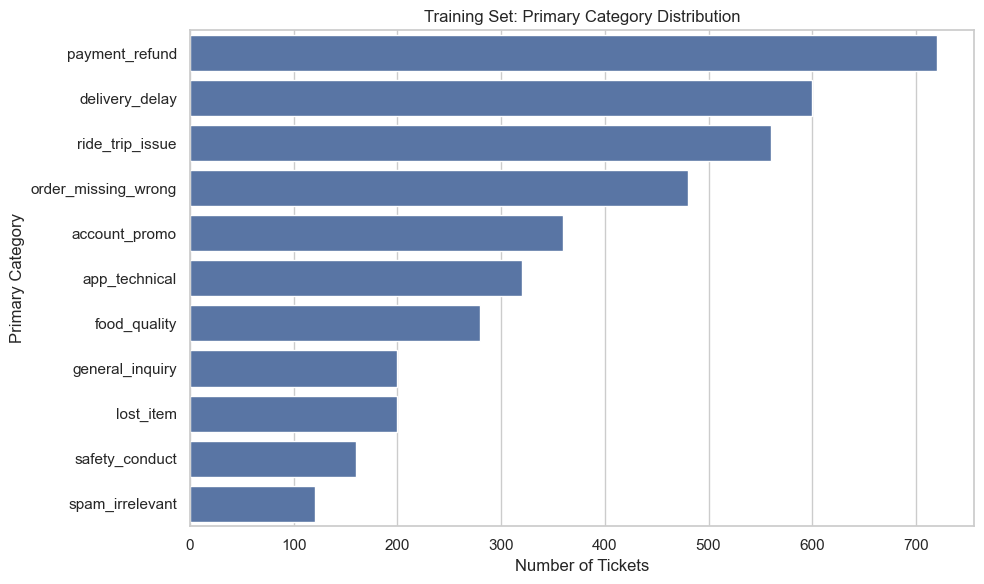

In [12]:
# Primary category distribution

plt.figure(figsize=(10, 6))

category_counts = train_df["category"].value_counts()

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Training Set: Primary Category Distribution")
plt.xlabel("Number of Tickets")
plt.ylabel("Primary Category")
plt.tight_layout()
plt.show()

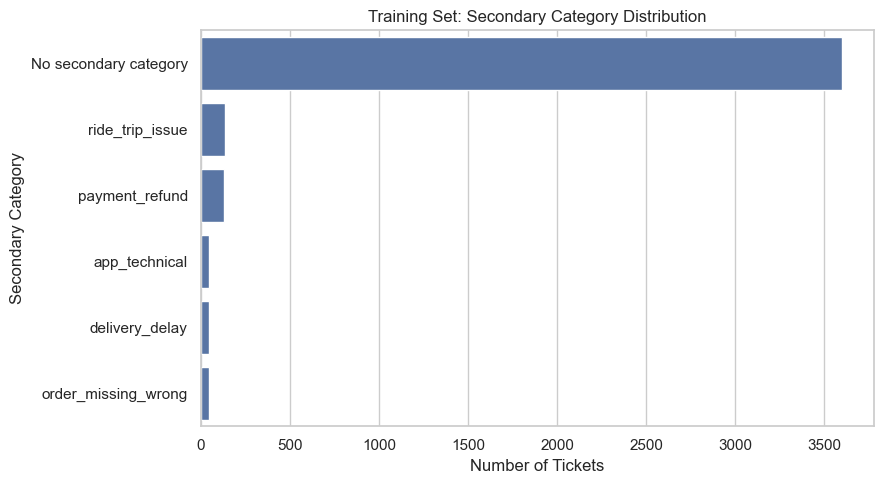

In [13]:
# Secondary category distribution

plt.figure(figsize=(9, 5))

secondary_counts = (
    train_df["secondary_category"]
    .fillna("No secondary category")
    .value_counts()
)

sns.barplot(
    x=secondary_counts.values,
    y=secondary_counts.index
)

plt.title("Training Set: Secondary Category Distribution")
plt.xlabel("Number of Tickets")
plt.ylabel("Secondary Category")
plt.tight_layout()
plt.show()

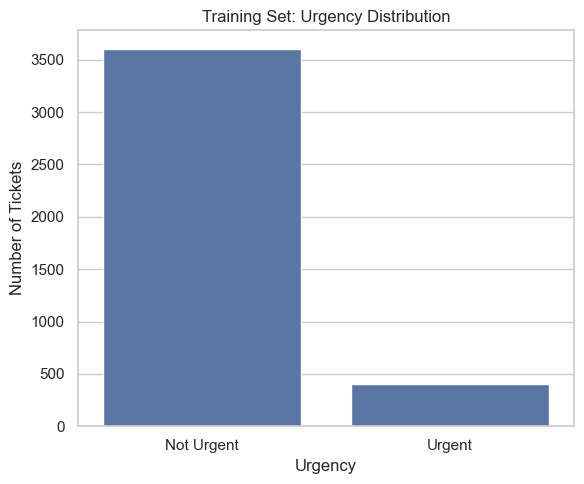

In [14]:
# Urgency distribution

plt.figure(figsize=(6, 5))

urgency_counts = (
    train_df["is_urgent"]
    .map({False: "Not Urgent", True: "Urgent"})
    .value_counts()
)

sns.barplot(
    x=urgency_counts.index,
    y=urgency_counts.values
)

plt.title("Training Set: Urgency Distribution")
plt.xlabel("Urgency")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

In [15]:
# Relationship between primary and secondary categories

category_secondary = pd.crosstab(
    train_df["category"],
    train_df["secondary_category"],
    dropna=False
)

print(category_secondary)

secondary_category   app_technical  delivery_delay  order_missing_wrong  \
category                                                                  
account_promo                   45               0                    0   
app_technical                    0               0                    0   
delivery_delay                   0               0                    0   
food_quality                     0               0                    0   
general_inquiry                  0               0                    0   
lost_item                        0               0                    0   
order_missing_wrong              0               0                    0   
payment_refund                   0              45                   45   
ride_trip_issue                  0               0                    0   
safety_conduct                   0               0                    0   
spam_irrelevant                  0               0                    0   

secondary_category   pay

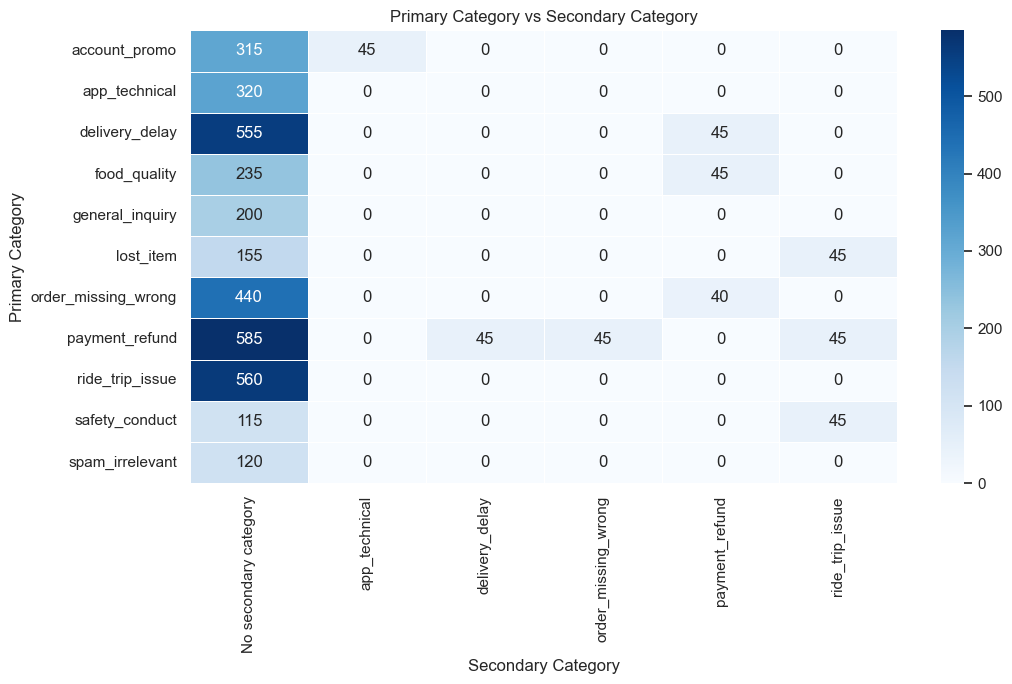

In [16]:
# Primary category vs secondary category heatmap

category_secondary_plot = (
    train_df.assign(
        secondary_category=train_df["secondary_category"].fillna("No secondary category")
    )
    .groupby(["category", "secondary_category"])
    .size()
    .unstack(fill_value=0)
)

plt.figure(figsize=(11, 7))

sns.heatmap(
    category_secondary_plot,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Primary Category vs Secondary Category")
plt.xlabel("Secondary Category")
plt.ylabel("Primary Category")
plt.tight_layout()
plt.show()

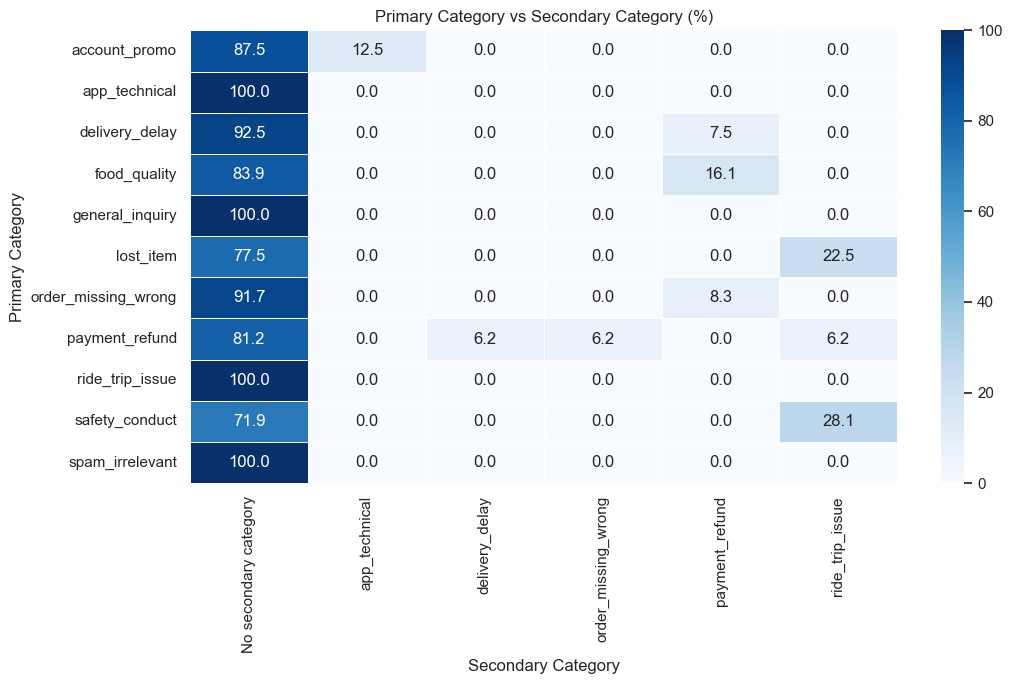

In [17]:
# Row-normalized primary vs secondary relationship

category_secondary_pct = (
    pd.crosstab(
        train_df["category"],
        train_df["secondary_category"].fillna("No secondary category"),
        normalize="index"
    ) * 100
)

plt.figure(figsize=(11, 7))

sns.heatmap(
    category_secondary_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Primary Category vs Secondary Category (%)")
plt.xlabel("Secondary Category")
plt.ylabel("Primary Category")
plt.tight_layout()
plt.show()

In [18]:
secondary_availability = (
    train_df.groupby("category")["secondary_category"]
    .apply(lambda x: x.notna().mean() * 100)
    .sort_values(ascending=False)
)

print("Percentage of tickets with a secondary category:")
print(secondary_availability.round(2))

Percentage of tickets with a secondary category:
category
safety_conduct         28.12
lost_item              22.50
payment_refund         18.75
food_quality           16.07
account_promo          12.50
order_missing_wrong     8.33
delivery_delay          7.50
app_technical           0.00
general_inquiry         0.00
ride_trip_issue         0.00
spam_irrelevant         0.00
Name: secondary_category, dtype: float64


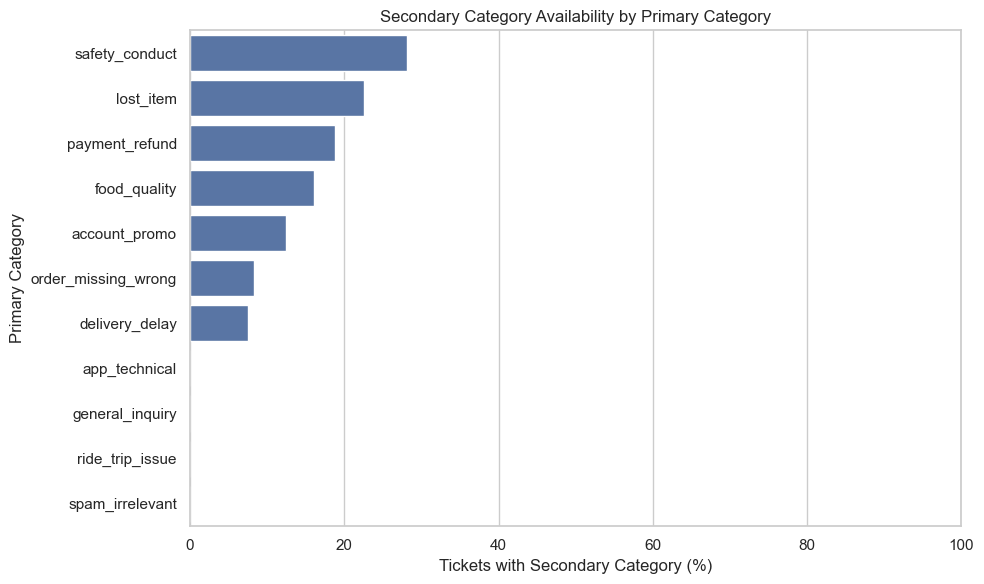

In [19]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=secondary_availability.values,
    y=secondary_availability.index
)

plt.title("Secondary Category Availability by Primary Category")
plt.xlabel("Tickets with Secondary Category (%)")
plt.ylabel("Primary Category")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

In [20]:
secondary_mapping = (
    train_df.dropna(subset=["secondary_category"])
    .groupby("category")["secondary_category"]
    .unique()
)

print("Secondary categories observed within each primary category:\n")

for category, secondary_values in secondary_mapping.items():
    print(f"{category}: {list(secondary_values)}")

Secondary categories observed within each primary category:

account_promo: ['app_technical']
delivery_delay: ['payment_refund']
food_quality: ['payment_refund']
lost_item: ['ride_trip_issue']
order_missing_wrong: ['payment_refund']
payment_refund: ['delivery_delay', 'order_missing_wrong', 'ride_trip_issue']
safety_conduct: ['ride_trip_issue']


In [21]:
validation_secondary_mapping = (
    validation_df.dropna(subset=["secondary_category"])
    .groupby("category")["secondary_category"]
    .unique()
)

print("Validation secondary categories observed within each primary category:\n")

for category, secondary_values in validation_secondary_mapping.items():
    print(f"{category}: {list(secondary_values)}")

Validation secondary categories observed within each primary category:

account_promo: ['app_technical']
delivery_delay: ['payment_refund']
food_quality: ['payment_refund']
lost_item: ['ride_trip_issue']
order_missing_wrong: ['payment_refund']
payment_refund: ['ride_trip_issue', 'order_missing_wrong', 'delivery_delay']
safety_conduct: ['ride_trip_issue']


In [22]:
train_df["text_length"] = train_df["text"].str.len()
train_df["word_count"] = train_df["text"].str.split().str.len()

train_df["subject_length"] = train_df["subject"].fillna("").str.len()
train_df["subject_word_count"] = (
    train_df["subject"]
    .fillna("")
    .str.split()
    .str.len()
)

print("=== Text Length Statistics ===")
print(train_df[[
    "text_length",
    "word_count",
    "subject_length",
    "subject_word_count"
]].describe().round(2))

=== Text Length Statistics ===
       text_length  word_count  subject_length  subject_word_count
count      4000.00     4000.00         4000.00             4000.00
mean        317.99       49.81            5.16                0.81
std         155.29       27.57            8.82                1.38
min          36.00        4.00            0.00                0.00
25%         197.00       30.00            0.00                0.00
50%         275.50       42.00            0.00                0.00
75%         406.00       58.00           11.00                2.00
max         985.00      178.00           76.00               15.00


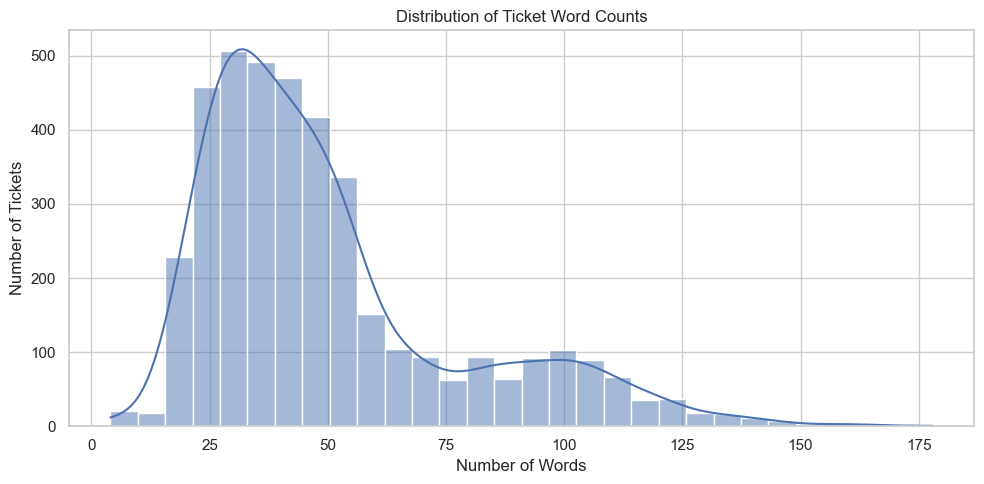

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["word_count"],
    bins=30,
    kde=True
)

plt.title("Distribution of Ticket Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

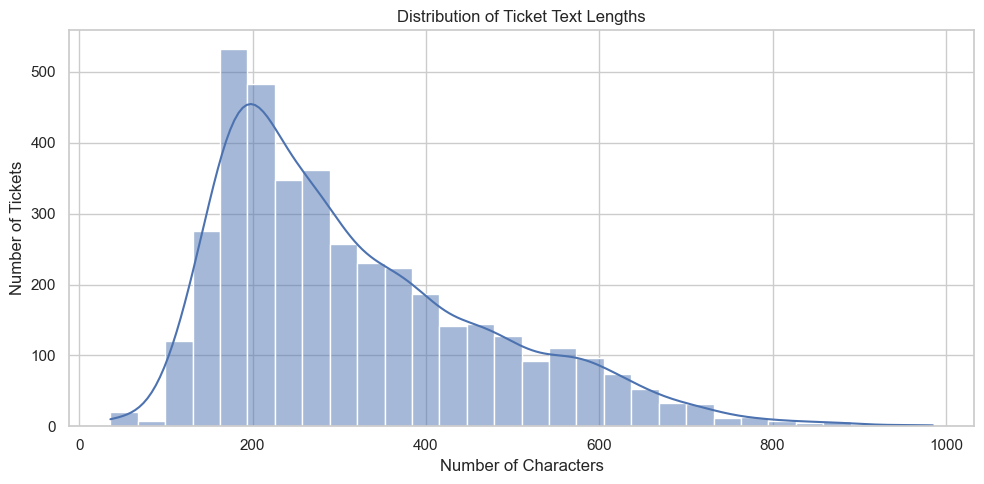

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["text_length"],
    bins=30,
    kde=True
)

plt.title("Distribution of Ticket Text Lengths")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

In [25]:
LANGUAGES = ["en", "si", "ta", "singlish", "tanglish", "mixed"]

print("=== TRAINING LANGUAGE DISTRIBUTION ===")

train_language_distribution = pd.DataFrame({
    "count": train_df["language"].value_counts().reindex(LANGUAGES, fill_value=0),
    "percentage": (
        train_df["language"]
        .value_counts(normalize=True)
        .mul(100)
        .reindex(LANGUAGES, fill_value=0)
        .round(2)
    )
})

print(train_language_distribution)

print("\n=== VALIDATION LANGUAGE DISTRIBUTION ===")

validation_language_distribution = pd.DataFrame({
    "count": validation_df["language"]
        .value_counts()
        .reindex(LANGUAGES, fill_value=0),
    "percentage": (
        validation_df["language"]
        .value_counts(normalize=True)
        .mul(100)
        .reindex(LANGUAGES, fill_value=0)
        .round(2)
    )
})

print(validation_language_distribution)

=== TRAINING LANGUAGE DISTRIBUTION ===
          count  percentage
language                   
en         1400        35.0
si          800        20.0
ta          600        15.0
singlish   1000        25.0
tanglish    100         2.5
mixed       100         2.5

=== VALIDATION LANGUAGE DISTRIBUTION ===
          count  percentage
language                   
en          280        35.0
si          160        20.0
ta          120        15.0
singlish    200        25.0
tanglish     20         2.5
mixed        20         2.5


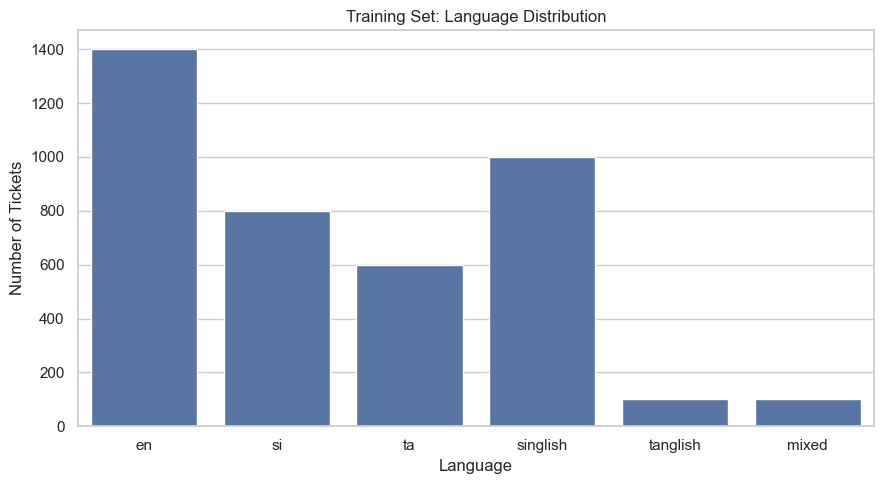

In [26]:
plt.figure(figsize=(9, 5))

language_counts = train_df["language"].value_counts().reindex(LANGUAGES)

sns.barplot(
    x=language_counts.index,
    y=language_counts.values
)

plt.title("Training Set: Language Distribution")
plt.xlabel("Language")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

In [27]:
category_language = pd.crosstab(
    train_df["category"],
    train_df["language"]
)

print("=== PRIMARY CATEGORY × LANGUAGE ===")
print(category_language)

=== PRIMARY CATEGORY × LANGUAGE ===
language              en  mixed   si  singlish   ta  tanglish
category                                                     
account_promo        126      9   72        90   54         9
app_technical        112      8   64        80   48         8
delivery_delay       210     15  120       150   90        15
food_quality          98      7   56        70   42         7
general_inquiry       70      5   40        50   30         5
lost_item             70      5   40        50   30         5
order_missing_wrong  168     12   96       120   72        12
payment_refund       252     18  144       180  108        18
ride_trip_issue      196     14  112       140   84        14
safety_conduct        56      4   32        40   24         4
spam_irrelevant       42      3   24        30   18         3


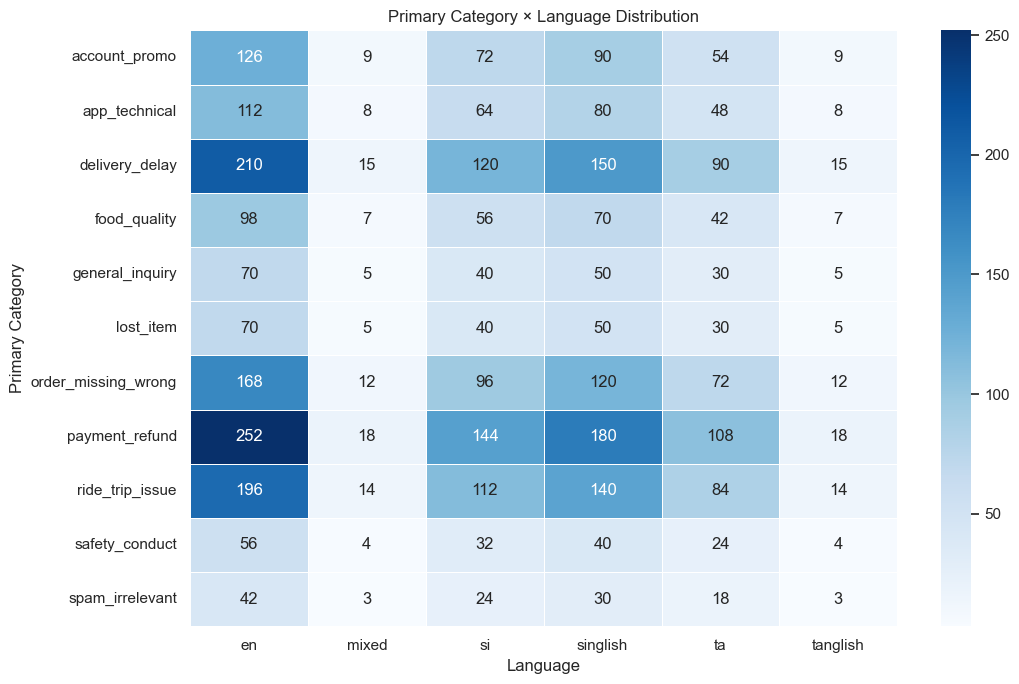

In [28]:
plt.figure(figsize=(11, 7))

sns.heatmap(
    category_language,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Primary Category × Language Distribution")
plt.xlabel("Language")
plt.ylabel("Primary Category")
plt.tight_layout()
plt.show()

In [29]:
category_language_pct = pd.crosstab(
    train_df["category"],
    train_df["language"],
    normalize="index"
) * 100

print("=== PRIMARY CATEGORY × LANGUAGE (%) ===")
print(category_language_pct.round(2))

=== PRIMARY CATEGORY × LANGUAGE (%) ===
language               en  mixed    si  singlish    ta  tanglish
category                                                        
account_promo        35.0    2.5  20.0      25.0  15.0       2.5
app_technical        35.0    2.5  20.0      25.0  15.0       2.5
delivery_delay       35.0    2.5  20.0      25.0  15.0       2.5
food_quality         35.0    2.5  20.0      25.0  15.0       2.5
general_inquiry      35.0    2.5  20.0      25.0  15.0       2.5
lost_item            35.0    2.5  20.0      25.0  15.0       2.5
order_missing_wrong  35.0    2.5  20.0      25.0  15.0       2.5
payment_refund       35.0    2.5  20.0      25.0  15.0       2.5
ride_trip_issue      35.0    2.5  20.0      25.0  15.0       2.5
safety_conduct       35.0    2.5  20.0      25.0  15.0       2.5
spam_irrelevant      35.0    2.5  20.0      25.0  15.0       2.5


In [30]:
print("=== CHANNEL DISTRIBUTION ===")

channel_counts = train_df["channel"].value_counts()
channel_percentages = (
    train_df["channel"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

channel_distribution = pd.DataFrame({
    "count": channel_counts,
    "percentage": channel_percentages
})

print(channel_distribution)

=== CHANNEL DISTRIBUTION ===
                 count  percentage
channel                           
chat              1800        45.0
email             1200        30.0
call_transcript   1000        25.0


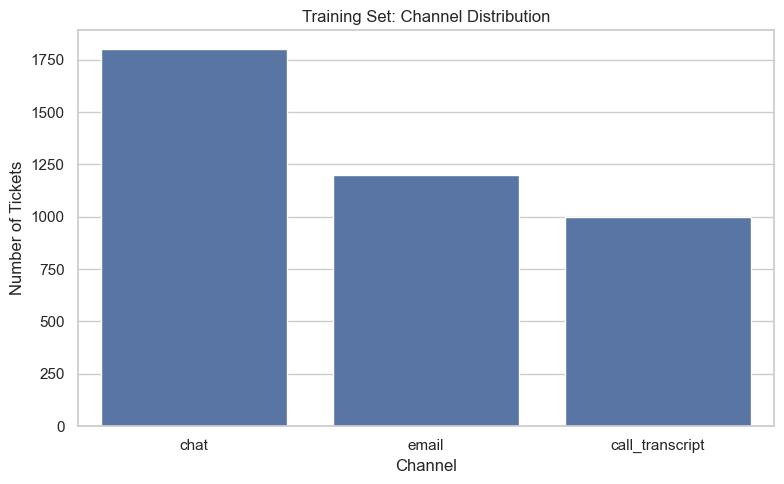

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=channel_counts.index,
    y=channel_counts.values
)

plt.title("Training Set: Channel Distribution")
plt.xlabel("Channel")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

In [34]:
# Check whether primary ticket categories are distributed
# differently across communication channels.
channel_category = pd.crosstab(
    train_df["channel"],
    train_df["category"]
)

print("=== CHANNEL × PRIMARY CATEGORY ===")
print(channel_category)

=== CHANNEL × PRIMARY CATEGORY ===
category         account_promo  app_technical  delivery_delay  food_quality  \
channel                                                                       
call_transcript             93             69             156            71   
chat                       152            156             273           123   
email                      115             95             171            86   

category         general_inquiry  lost_item  order_missing_wrong  \
channel                                                            
call_transcript               44         48                  123   
chat                          91         88                  222   
email                         65         64                  135   

category         payment_refund  ride_trip_issue  safety_conduct  \
channel                                                            
call_transcript             189              150              26   
chat                    

In [ ]:
# Compare category proportions within each communication channel.
# This removes the effect of different channel sample sizes and
# shows whether some categories are more common in specific channels.
channel_category_pct = pd.crosstab(
    train_df["channel"],
    train_df["category"],
    normalize="index"
) * 100

print("=== CHANNEL × PRIMARY CATEGORY (%) ===")
print(channel_category_pct.round(2))

=== CHANNEL × PRIMARY CATEGORY (%) ===
category         account_promo  app_technical  delivery_delay  food_quality  \
channel                                                                       
call_transcript           9.30           6.90           15.60          7.10   
chat                      8.44           8.67           15.17          6.83   
email                     9.58           7.92           14.25          7.17   

category         general_inquiry  lost_item  order_missing_wrong  \
channel                                                            
call_transcript             4.40       4.80                12.30   
chat                        5.06       4.89                12.33   
email                       5.42       5.33                11.25   

category         payment_refund  ride_trip_issue  safety_conduct  \
channel                                                            
call_transcript           18.90            15.00            2.60   
chat                

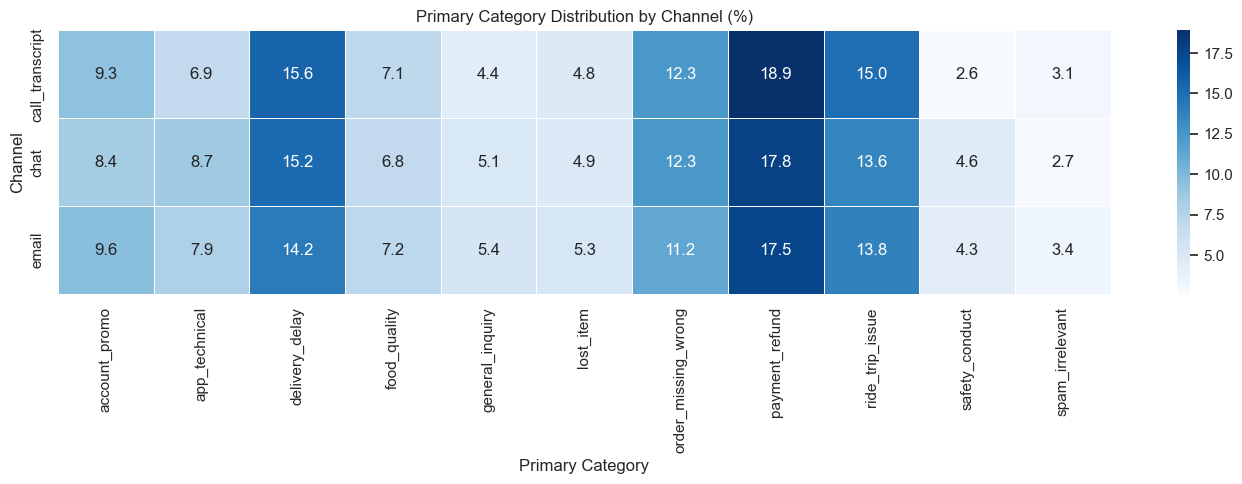

In [36]:
# Visualize the within-channel category proportions to identify
# noticeable differences in category patterns across channels.
plt.figure(figsize=(14, 5))

sns.heatmap(
    channel_category_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Primary Category Distribution by Channel (%)")
plt.xlabel("Primary Category")
plt.ylabel("Channel")
plt.tight_layout()
plt.show()

In [38]:
# Check language distribution across communication channels.
channel_language = pd.crosstab(
    train_df["channel"],
    train_df["language"]
)

print("=== CHANNEL × LANGUAGE ===")
print(channel_language)

=== CHANNEL × LANGUAGE ===
language          en  mixed   si  singlish   ta  tanglish
channel                                                  
call_transcript  356     22  201       261  140        20
chat             637     45  356       441  278        43
email            407     33  243       298  182        37


In [39]:
# Compare language proportions within each channel.
channel_language_pct = pd.crosstab(
    train_df["channel"],
    train_df["language"],
    normalize="index"
) * 100

print("=== CHANNEL × LANGUAGE (%) ===")
print(channel_language_pct.round(2))

=== CHANNEL × LANGUAGE (%) ===
language            en  mixed     si  singlish     ta  tanglish
channel                                                        
call_transcript  35.60   2.20  20.10     26.10  14.00      2.00
chat             35.39   2.50  19.78     24.50  15.44      2.39
email            33.92   2.75  20.25     24.83  15.17      3.08


In [40]:
# Check urgency distribution within each primary category.
category_urgency_pct = pd.crosstab(
    train_df["category"],
    train_df["is_urgent"],
    normalize="index"
) * 100

print("=== PRIMARY CATEGORY × URGENCY (%) ===")
print(category_urgency_pct.round(2))

=== PRIMARY CATEGORY × URGENCY (%) ===
is_urgent             False  True 
category                          
account_promo        100.00   0.00
app_technical        100.00   0.00
delivery_delay        88.00  12.00
food_quality          82.86  17.14
general_inquiry      100.00   0.00
lost_item             90.00  10.00
order_missing_wrong   95.83   4.17
payment_refund        88.89  11.11
ride_trip_issue       92.86   7.14
safety_conduct        25.00  75.00
spam_irrelevant      100.00   0.00


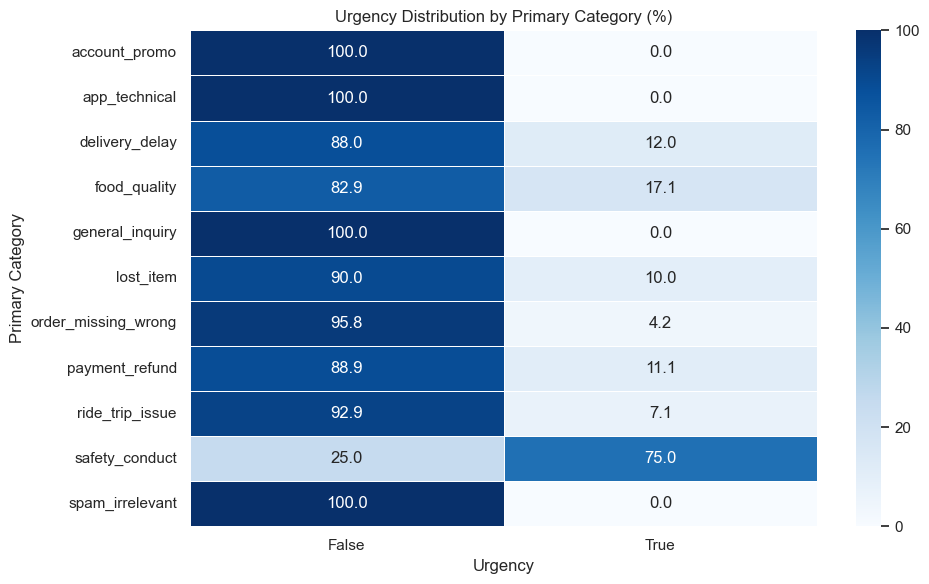

In [41]:
# Visualize the proportion of urgent tickets within each category.
plt.figure(figsize=(10, 6))

sns.heatmap(
    category_urgency_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Urgency Distribution by Primary Category (%)")
plt.xlabel("Urgency")
plt.ylabel("Primary Category")
plt.tight_layout()
plt.show()

In [42]:
# Check whether urgency rates differ across languages.
language_urgency_pct = pd.crosstab(
    train_df["language"],
    train_df["is_urgent"],
    normalize="index"
) * 100

print("=== LANGUAGE × URGENCY (%) ===")
print(language_urgency_pct.round(2))

=== LANGUAGE × URGENCY (%) ===
is_urgent  False  True 
language               
en         90.50   9.50
mixed      91.00   9.00
si         89.75  10.25
singlish   90.10   9.90
ta         88.67  11.33
tanglish   91.00   9.00


In [43]:
# Compare ticket length across primary categories.
category_text_stats = (
    train_df.groupby("category")["word_count"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
)

print("=== TEXT LENGTH BY PRIMARY CATEGORY ===")
print(category_text_stats.round(2))

=== TEXT LENGTH BY PRIMARY CATEGORY ===
                     count   mean  median  min  max
category                                           
account_promo          360  51.80    43.0    6  144
payment_refund         720  50.99    42.0    4  166
lost_item              200  50.99    45.0    5  144
delivery_delay         600  50.80    43.0    4  168
safety_conduct         160  50.79    42.0   21  128
food_quality           280  50.57    43.0    5  159
ride_trip_issue        560  49.75    43.0    5  178
general_inquiry        200  49.06    40.0    7  115
order_missing_wrong    480  48.69    41.0    4  153
app_technical          320  46.95    39.0    5  161
spam_irrelevant        120  40.54    34.0   14  113


In [45]:
# Compare ticket length across language groups.
language_text_stats = (
    train_df.groupby("language")["word_count"]
    .agg(["count", "mean", "median", "min", "max"])
)

print("=== TEXT LENGTH BY LANGUAGE ===")
print(language_text_stats.round(2))

=== TEXT LENGTH BY LANGUAGE ===
          count   mean  median  min  max
language                                
en         1400  72.61    73.5    6  178
mixed       100  43.72    42.5   26   76
si          800  38.11    35.0    4   80
singlish   1000  39.40    38.0    5   75
ta          600  32.89    31.0    5   72
tanglish    100  36.01    33.5    6   71


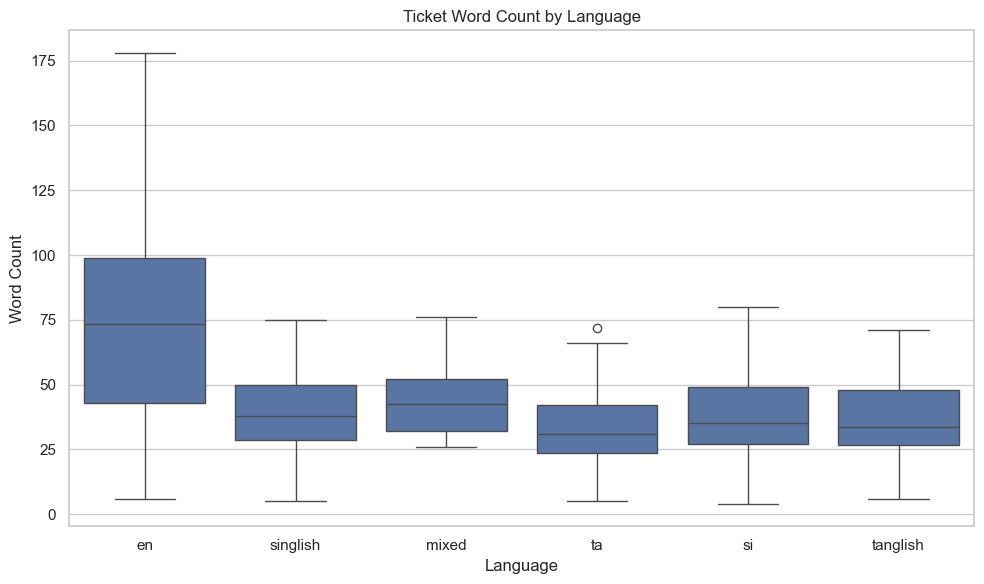

In [46]:
# Visualize ticket length differences between language groups.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=train_df,
    x="language",
    y="word_count"
)

plt.title("Ticket Word Count by Language")
plt.xlabel("Language")
plt.ylabel("Word Count")
plt.tight_layout()
plt.show()

In [47]:
# Compare ticket length between urgent and non-urgent tickets.
urgency_text_stats = (
    train_df.groupby("is_urgent")["word_count"]
    .agg(["count", "mean", "median", "min", "max"])
)

print("=== TEXT LENGTH BY URGENCY ===")
print(urgency_text_stats.round(2))

=== TEXT LENGTH BY URGENCY ===
           count   mean  median  min  max
is_urgent                                
False       3600  49.41    41.0    4  178
True         400  53.42    47.0   20  148


In [49]:
# Check whether tickets commonly contain numerical information.
has_digits = train_df["text"].str.contains(r"\d", regex=True)

print("Tickets containing digits:")
print(has_digits.value_counts())
print("\nPercentages:")
print((has_digits.value_counts(normalize=True) * 100).round(2))

Tickets containing digits:
text
False    2492
True     1508
Name: count, dtype: int64

Percentages:
text
False    62.3
True     37.7
Name: proportion, dtype: float64


In [51]:
# Check whether tickets contain punctuation characters.
has_punctuation = train_df["text"].str.contains(
    r"[^\w\s]",
    regex=True
)

print("Tickets containing punctuation")
print(has_punctuation.value_counts())

print("\nPercentages:")
print((has_punctuation.value_counts(normalize=True) * 100).round(2))

Tickets containing punctuation
text
True     3811
False     189
Name: count, dtype: int64

Percentages:
text
True     95.28
False     4.72
Name: proportion, dtype: float64


In [53]:
# Check how often tickets contain uppercase letters.
has_uppercase = train_df["text"].str.contains(
    r"[A-Z]",
    regex=True
)

print("Tickets containing uppercase letters")
print(has_uppercase.value_counts())

print("\nPercentages:")
print((has_uppercase.value_counts(normalize=True) * 100).round(2))

Tickets containing uppercase letters
text
False    2323
True     1677
Name: count, dtype: int64

Percentages:
text
False    58.08
True     41.92
Name: proportion, dtype: float64


In [54]:
# Check whether subject availability differs across primary categories.
subject_available = train_df["subject"].notna()

subject_category_pct = pd.crosstab(
    train_df["category"],
    subject_available,
    normalize="index"
) * 100

print("=== SUBJECT AVAILABILITY BY PRIMARY CATEGORY (%) ===")
print(subject_category_pct.round(2))

=== SUBJECT AVAILABILITY BY PRIMARY CATEGORY (%) ===
subject              False  True 
category                         
account_promo        68.06  31.94
app_technical        70.31  29.69
delivery_delay       71.50  28.50
food_quality         69.29  30.71
general_inquiry      67.50  32.50
lost_item            68.00  32.00
order_missing_wrong  71.88  28.12
payment_refund       70.83  29.17
ride_trip_issue      70.36  29.64
safety_conduct       67.50  32.50
spam_irrelevant      65.83  34.17


In [55]:
# Examine subject length only for tickets where a subject exists.
subject_stats = (
    train_df.loc[train_df["subject"].notna(), "subject_word_count"]
    .describe()
)

print("=== NON-MISSING SUBJECT LENGTH ===")
print(subject_stats.round(2))

=== NON-MISSING SUBJECT LENGTH ===
count    1200.00
mean        2.71
std         1.10
min         1.00
25%         2.00
50%         3.00
75%         3.00
max        15.00
Name: subject_word_count, dtype: float64


In [56]:
# Inspect a small sample of available subjects.
print("=== SAMPLE SUBJECTS ===")
print(train_df.loc[
    train_df["subject"].notna(),
    "subject"
].sample(15, random_state=42).to_string(index=False))

=== SAMPLE SUBJECTS ===
             මගේ පණිවිඩය
விவரங்களைச் சரிபாருங்கள்
               Help ekak
  Request for assistance
    இதுபற்றிப் பாருங்கள்
               Help ekak
   Details check karanna
              En message
               Help ekak
  Request for assistance
  Request for assistance
  Request for assistance
    විස්තර පරීක්ෂා කරන්න
            මේ ගැන බලන්න
   Condition of the meal


In [57]:
# Compare primary category distributions between train and validation.
train_category_pct = (
    train_df["category"]
    .value_counts(normalize=True)
    .mul(100)
)

validation_category_pct = (
    validation_df["category"]
    .value_counts(normalize=True)
    .mul(100)
)

category_distribution_comparison = pd.DataFrame({
    "train_pct": train_category_pct,
    "validation_pct": validation_category_pct
}).round(2)

print("=== PRIMARY CATEGORY DISTRIBUTION ===")
print(category_distribution_comparison)

=== PRIMARY CATEGORY DISTRIBUTION ===
                     train_pct  validation_pct
category                                      
payment_refund            18.0            18.0
delivery_delay            15.0            15.0
ride_trip_issue           14.0            14.0
order_missing_wrong       12.0            12.0
account_promo              9.0             9.0
app_technical              8.0             8.0
food_quality               7.0             7.0
general_inquiry            5.0             5.0
lost_item                  5.0             5.0
safety_conduct             4.0             4.0
spam_irrelevant            3.0             3.0


In [58]:
# Compare urgency distributions between train and validation.
urgency_distribution_comparison = pd.DataFrame({
    "train_pct": (
        train_df["is_urgent"]
        .value_counts(normalize=True)
        .mul(100)
    ),
    "validation_pct": (
        validation_df["is_urgent"]
        .value_counts(normalize=True)
        .mul(100)
    )
}).round(2)

print("\n=== URGENCY DISTRIBUTION ===")
print(urgency_distribution_comparison)


=== URGENCY DISTRIBUTION ===
           train_pct  validation_pct
is_urgent                           
False           90.0            90.0
True            10.0            10.0


# Exploratory Data Analysis Findings

## 1. Dataset Loading and Shape

**Purpose:** Verify the available training and validation datasets.

| Dataset    |  Rows | Columns |
| ---------- | ----: | ------: |
| Train      | 4,000 |       8 |
| Validation |   800 |       8 |

Expected columns:

```text
ticket_id
channel
subject
text
language
category
secondary_category
is_urgent
```

### Finding

The dataset contains 4,000 training tickets and 800 validation tickets with the expected schema.

---

## 2. Schema and Data Types

### Finding

* Column order matches the expected schema.
* `is_urgent` is Boolean.
* Other fields are stored as object/string data.
* No unexpected columns were found.

---

## 3. Missing Values

| Column               | Train Missing | Validation Missing |
| -------------------- | ------------: | -----------------: |
| `ticket_id`          |            0% |                 0% |
| `channel`            |            0% |                 0% |
| `subject`            |       **70%** |            **70%** |
| `text`               |            0% |                 0% |
| `language`           |            0% |                 0% |
| `category`           |            0% |                 0% |
| `secondary_category` |       **90%** |            **90%** |
| `is_urgent`          |            0% |                 0% |

### Finding

`text` is always available, making it the primary textual input.

`subject` is highly sparse and should not be treated as the main text source.

`secondary_category` is intentionally a partial target and requires separate handling.

---

## 4. Duplicate and ID Integrity

### Finding

* Train ticket IDs: 4,000 unique out of 4,000.
* Validation ticket IDs: 800 unique out of 800.
* Duplicate IDs: 0 in both datasets.
* Duplicate complete rows: 0 in both datasets.
* Train/validation ticket ID overlap: 0.

### Modeling implication

`ticket_id` should not be used as a predictive feature.

There is no obvious ID-based leakage between training and validation.

---

# 5. Primary Category Distribution

| Category              | Count | Percentage |
| --------------------- | ----: | ---------: |
| `payment_refund`      |   720 |        18% |
| `delivery_delay`      |   600 |        15% |
| `ride_trip_issue`     |   560 |        14% |
| `order_missing_wrong` |   480 |        12% |
| `account_promo`       |   360 |         9% |
| `app_technical`       |   320 |         8% |
| `food_quality`        |   280 |         7% |
| `general_inquiry`     |   200 |         5% |
| `lost_item`           |   200 |         5% |
| `safety_conduct`      |   160 |         4% |
| `spam_irrelevant`     |   120 |         3% |

### Finding

The largest class is `payment_refund` at 18%, while the smallest is `spam_irrelevant` at 3%.

The largest-to-smallest class ratio is approximately **6:1**.

### Modeling implication

Accuracy alone is not sufficient.

Primary classification should emphasize:

* Macro-F1
* Per-class precision, recall, and F1
* Confusion matrix
* Performance on minority classes

---

# 6. Primary Category vs Secondary Category

The secondary category is strongly constrained by the primary category.

Observed mappings include:

| Primary Category      | Observed Secondary Categories                              |
| --------------------- | ---------------------------------------------------------- |
| `account_promo`       | `app_technical`                                            |
| `delivery_delay`      | `payment_refund`                                           |
| `food_quality`        | `payment_refund`                                           |
| `lost_item`           | `ride_trip_issue`                                          |
| `order_missing_wrong` | `payment_refund`                                           |
| `payment_refund`      | `delivery_delay`, `order_missing_wrong`, `ride_trip_issue` |
| `safety_conduct`      | `ride_trip_issue`                                          |

The remaining primary categories have no secondary labels in the dataset.

### Finding

Secondary labels are not independent of primary categories.

### Modeling implication

A **hierarchical or constrained secondary prediction strategy** may be useful.

However, this should be investigated after establishing the primary baseline rather than implemented prematurely.

---

# 7. Secondary Category Availability

Percentage of tickets containing a secondary category:

| Primary Category      | Secondary Available |
| --------------------- | ------------------: |
| `safety_conduct`      |              28.12% |
| `lost_item`           |              22.50% |
| `payment_refund`      |              18.75% |
| `food_quality`        |              16.07% |
| `account_promo`       |              12.50% |
| `order_missing_wrong` |               8.33% |
| `delivery_delay`      |               7.50% |
| `app_technical`       |                  0% |
| `general_inquiry`     |                  0% |
| `ride_trip_issue`     |                  0% |
| `spam_irrelevant`     |                  0% |

### Finding

Secondary labels are available for only a subset of tickets and are strongly associated with certain primary categories.

---

# 8. Text Length

Overall text statistics:

| Statistic | Characters | Words |
| --------- | ---------: | ----: |
| Mean      |     317.99 | 49.81 |
| Median    |     275.50 |    42 |
| Minimum   |         36 |     4 |
| Maximum   |        985 |   178 |

### Finding

Tickets have substantial variation in length, but most contain relatively moderate amounts of text.

### Modeling implication

The textual content itself should be more important than simple length-based features.

---

# 9. Language Distribution

| Language   | Train | Validation |
| ---------- | ----: | ---------: |
| `en`       |   35% |        35% |
| `si`       |   20% |        20% |
| `ta`       |   15% |        15% |
| `singlish` |   25% |        25% |
| `tanglish` |  2.5% |       2.5% |
| `mixed`    |  2.5% |       2.5% |

### Finding

The language distribution is exactly consistent between train and validation.

### Modeling implication

Rare languages, particularly `tanglish` and `mixed`, should receive separate evaluation because overall metrics may hide poor performance on these groups.

---

# 10. Primary Category vs Language

Every primary category follows the same language proportions:

* English: 35%
* Sinhala: 20%
* Tamil: 15%
* Singlish: 25%
* Tanglish: 2.5%
* Mixed: 2.5%

### Finding

Language and primary category are effectively independent in this dataset.

### Modeling implication

Language-specific performance differences are less likely to be caused by category distribution differences.

---

# 11. Channel Distribution

| Channel           | Count | Percentage |
| ----------------- | ----: | ---------: |
| `chat`            | 1,800 |        45% |
| `email`           | 1,200 |        30% |
| `call_transcript` | 1,000 |        25% |

### Finding

Channel distribution is moderately imbalanced but all three channels have sufficient samples.

No channel is too rare to evaluate.

---

# 12. Channel vs Primary Category

Category proportions were relatively similar across all channels.

Examples:

| Category              |   Call |   Chat |  Email |
| --------------------- | -----: | -----: | -----: |
| `payment_refund`      | 18.90% | 17.83% | 17.50% |
| `delivery_delay`      | 15.60% | 15.17% | 14.25% |
| `ride_trip_issue`     | 15.00% | 13.56% | 13.83% |
| `order_missing_wrong` | 12.30% | 12.33% | 11.25% |
| `spam_irrelevant`     |  3.10% |  2.67% |  3.42% |

### Finding

There is no strong channel-category relationship.

### Modeling implication

`channel` should be **tested as a metadata feature**, rather than automatically assumed to be important or discarded.

---

# 13. Channel vs Language

Language proportions were also similar across channels.

| Language |   Call |   Chat |  Email |
| -------- | -----: | -----: | -----: |
| English  | 35.60% | 35.39% | 33.92% |
| Sinhala  | 20.10% | 19.78% | 20.25% |
| Tamil    | 14.00% | 15.44% | 15.17% |
| Singlish | 26.10% | 24.50% | 24.83% |
| Tanglish |  2.00% |  2.39% |  3.08% |
| Mixed    |  2.20% |  2.50% |  2.75% |

### Finding

There is no major channel-language imbalance.

### Modeling implication

`channel` does not appear to be acting as a strong proxy for language.

---

# 14. Primary Category vs Urgency

| Category              |     Urgent |
| --------------------- | ---------: |
| `safety_conduct`      | **75.00%** |
| `food_quality`        |     17.14% |
| `delivery_delay`      |     12.00% |
| `payment_refund`      |     11.11% |
| `lost_item`           |     10.00% |
| `ride_trip_issue`     |      7.14% |
| `order_missing_wrong` |      4.17% |
| `account_promo`       |         0% |
| `app_technical`       |         0% |
| `general_inquiry`     |         0% |
| `spam_irrelevant`     |         0% |

### Finding

Urgency has a strong relationship with primary category.

The strongest signal is `safety_conduct`, where 75% of tickets are urgent.

Four categories contain no urgent tickets in the training set.

### Modeling implication

Primary category may provide useful information for urgency prediction.

However, the true category cannot be used directly during inference because it is unknown. A hierarchical approach using the **predicted** primary category could be investigated later.

---

# 15. Language vs Urgency

| Language | Urgent |
| -------- | -----: |
| English  |  9.50% |
| Mixed    |  9.00% |
| Sinhala  | 10.25% |
| Singlish |  9.90% |
| Tamil    | 11.33% |
| Tanglish |  9.00% |

### Finding

Urgency rates are very similar across languages.

The largest difference is only around 2.3 percentage points.

### Modeling implication

There is no major language-urgency imbalance in the dataset.

---

# 16. Text Length vs Primary Category

Mean word counts ranged from:

* `account_promo`: 51.80
* `payment_refund`: 50.99
* `lost_item`: 50.99
* `delivery_delay`: 50.80
* `safety_conduct`: 50.79
* `food_quality`: 50.57
* `ride_trip_issue`: 49.75
* `general_inquiry`: 49.06
* `order_missing_wrong`: 48.69
* `app_technical`: 46.95
* `spam_irrelevant`: 40.54

### Finding

Most categories have similar ticket lengths.

`spam_irrelevant` is somewhat shorter than the other categories.

### Modeling implication

Word count alone is unlikely to be a strong primary-category predictor.

---

# 17. Text Length vs Language

| Language | Mean Words | Median |
| -------- | ---------: | -----: |
| English  |  **72.61** |   73.5 |
| Mixed    |      43.72 |   42.5 |
| Singlish |      39.40 |   38.0 |
| Sinhala  |      38.11 |   35.0 |
| Tanglish |      36.01 |   33.5 |
| Tamil    |  **32.89** |   31.0 |

### Finding

There is a substantial difference in ticket length across language groups.

English tickets are considerably longer on average than the other language groups.

### Modeling implication

Raw word count should not be treated as a universal indicator of information content.

This strengthens the case for multilingual text representations and character-level features.

---

# 18. Text Length vs Urgency

| Urgency    | Mean Words | Median |
| ---------- | ---------: | -----: |
| Non-urgent |      49.41 |     41 |
| Urgent     |      53.42 |     47 |

### Finding

Urgent tickets are slightly longer on average, but the distributions overlap substantially.

### Modeling implication

Text length alone is unlikely to be a strong urgency predictor.

---

# 19. Digit Usage

| Contains Digits | Count | Percentage |
| --------------- | ----: | ---------: |
| No              | 2,492 |      62.3% |
| Yes             | 1,508 |  **37.7%** |

### Finding

Digits occur in more than one-third of tickets.

They may represent:

* Order numbers
* Transaction IDs
* OTPs
* Dates
* Times
* Amounts
* Error codes

### Modeling implication

Digits should **not be removed blindly** during preprocessing.

The initial TF-IDF experiments should preserve them.

---

# 20. Punctuation and Capitalization

### Punctuation

* Tickets containing punctuation: **95.28%**
* Tickets without punctuation: 4.72%

### Uppercase

* Tickets containing uppercase letters: **41.92%**
* Tickets without uppercase letters: 58.08%

### Finding

Punctuation is extremely common, while uppercase usage is also substantial.

### Modeling implication

Aggressive text cleaning should be avoided.

Initial preprocessing should be conservative, and choices such as lowercasing should be tested experimentally.

---

# 21. Subject Analysis

## Subject availability

Subjects are missing in **70%** of tickets.

Subject availability by category is relatively consistent, generally around 28% to 33%.

### Finding

Missing subjects are not strongly concentrated in a particular primary category.

## Subject length

For the 1,200 tickets with subjects:

| Statistic       | Words |
| --------------- | ----: |
| Mean            |  2.71 |
| Median          |     3 |
| 75th percentile |     3 |
| Maximum         |    15 |

Example subjects include:

```text
Help ekak
Request for assistance
En message
මේ ගැන බලන්න
විස්තර පරීක්ෂා කරන්න
Condition of the meal
```

### Finding

Subjects are usually very short and often generic, although some contain useful information.

### Modeling implication

`text` should remain the primary textual input.

We should experimentally compare:

```text
text
```

against:

```text
subject + text
```

Rather than creating a complex subject-specific model.

---

# Final EDA Summary

## Dataset quality

The dataset is structurally clean:

* Correct schema
* No duplicate IDs
* No train/validation ID overlap
* Text available for every ticket
* Consistent train/validation distributions

## Main modeling challenges

The major challenges identified are:

1. **Multilingual and transliterated text**
2. **Primary-class imbalance**
3. **Urgency imbalance**
4. **Sparse subject field**
5. **Partial secondary labels**
6. **Spelling and writing-style variation**
7. **Different text lengths across languages**

## Preprocessing implications

The EDA supports **conservative preprocessing**.

We should avoid blindly:

* Removing punctuation
* Removing digits
* Removing non-English characters
* Aggressively normalizing transliterated text
* Discarding short text
* Treating missing subjects as missing tickets

## Initial modeling direction

The EDA supports the following experiment sequence:

```text
TF-IDF Word N-grams
        │
        ├── Text only
        └── Subject + Text

TF-IDF Character N-grams
        │
        ├── Text only
        └── Subject + Text

Word + Character TF-IDF
        │
        └── Compare against individual representations

Metadata experiments
        │
        ├── + language
        ├── + channel
        └── + language + channel

Advanced multilingual model
        │
        └── XLM-R
```

For primary classification, compare **Logistic Regression** and **Linear SVM** as strong classical baselines.

For urgency, evaluate particularly:

* Urgent precision
* Urgent recall
* Urgent F1
* Macro-F1
* Confusion matrix

For multilingual evaluation, report performance by:

```text
en
si
ta
singlish
tanglish
mixed
```

For the secondary target, the strong relationship with primary category should be investigated when designing the final prediction strategy.

## Key EDA conclusion

The dataset does not require aggressive cleaning or complicated handcrafted features. The strongest evidence points toward **robust text representations**, particularly **word and character n-grams**, followed by controlled metadata experiments and an advanced multilingual transformer comparison.
